# Kiểm tra thị giác máy tính

Với một bài ảnh mới có thời hạn, runtime và một mẫu đầu ra, chọn model chỉ là một đoạn của công việc. Buổi kiểm tra này ôn cách đi từ hợp đồng của đề đến một pipeline nạp lại được và chấm được, bằng các công cụ của Chương 5. Đề kiểm tra và bài tập của chương nằm ở mục bài tập; phần dưới là phần ôn và cách chữa kết quả.

> **Mục tiêu sau buổi kiểm tra**
>
> - Nhận dạng classification, detection, segmentation hoặc retrieval từ đầu ra cần nộp.
> - Dựng baseline và validation hợp lệ trước khi thử model lớn.
> - Chọn một thay đổi dựa trên lỗi đã đo và kiểm runtime.
> - Nạp lại checkpoint, đối chiếu sample và giải thích vì sao chọn cấu hình cuối.

## Đọc câu hỏi trước khi đọc tên model

Cùng một ảnh lớp học có thể cần một nhãn hoạt động, danh sách người, mask vùng bàn hoặc xếp hạng ảnh theo câu. Viết rõ một hàng đầu ra gồm gì, metric gì, chiều tốt là cao hay thấp và ảnh không có vật thể được biểu diễn thế nào.



Classification thường nộp logits, xác suất hoặc nhãn; detection nộp class, box, score; segmentation nộp mask hoặc RLE; retrieval nộp thứ hạng. Metric đi theo dạng đầu ra: log loss chấm xác suất của từng lớp nên cần nộp xác suất chứ không nộp nhãn; accuracy của một classifier không chọn được score threshold cho bài đếm; Dice tính trên mask không thay được scorer detection vốn ghép box theo IoU.

**Hỏi nhanh.** Đề phân loại 3 lớp chấm bằng log loss, tức trung bình $-\ln p$ của lớp đúng, và scorer kẹp $p$ vào $[10^{-15}, 1]$. Model đúng 90% ảnh validation. Nếu nộp one-hot theo argmax, tức xác suất 1 cho lớp dự đoán và 0 cho các lớp khác, thì log loss xấp xỉ bao nhiêu?

- A. 0.10
- B. 1.10
- C. 3.45
- D. 0.11

<details><summary>Đáp án</summary>

C. 3.45

90% ảnh đúng góp $-\ln 1 = 0$. 10% ảnh sai có $p = 10^{-15}$ ở lớp đúng, mỗi ảnh góp $-\ln 10^{-15} \approx 34.5$. Vậy trung bình khoảng $0.1\times 34.5 = 3.45$. Con số này còn tệ hơn đoán đều ba lớp, vốn chỉ có $\ln 3 \approx 1.10$. 0.10 là tỉ lệ sai. 0.11 là $-\ln 0.9$. Đề chấm log loss thì phải nộp xác suất softmax, và kiểm tổng mỗi hàng bằng 1. Một model đúng 90% mà nộp sai dạng vẫn thua bài nộp không học gì.

</details>



Đọc các điều kiện môi trường trong thông báo và đề: phần cứng được cấp, có Internet hay không, asset nào được phép, thời gian train và runtime được tính thế nào. Có T4 vẫn phải đo bộ nhớ khả dụng; tên GPU chưa cho biết pipeline chạy hết bao lâu. Thời gian đo trên CPU ở các bài của chương không quy đổi được sang T4; phải đo lại trên đúng loại máy chấm.

**Hỏi nhanh.** Máy chấm không có Internet. Đề cho dùng model công khai nếu đính kèm trọng số làm asset. Notebook gọi `resnet50(weights="IMAGENET1K_V2")` và chạy tốt trên máy cá nhân. Có rủi ro gì, và sửa thế nào?

- A. Không rủi ro, vì trọng số đã có trong cache của máy cá nhân
- B. Lệnh tải sẽ lỗi, nên phải nạp trọng số từ asset và chạy thử khi tắt mạng
- C. Đổi sang `weights=None` để khỏi tải, giữ các bước còn lại
- D. Bọc lệnh tải trong `try/except` để notebook chạy tiếp

<details><summary>Đáp án</summary>

B. Lệnh tải sẽ lỗi, nên phải nạp trọng số từ asset và chạy thử khi tắt mạng

Máy chấm là một môi trường khác, cache của máy cá nhân không đi theo sang. Không có mạng thì lệnh tải trọng số sẽ lỗi. Cách đúng là đính kèm file trọng số được phép, nạp bằng `load_state_dict` từ đường dẫn cục bộ, rồi chạy thử cả pipeline khi tắt mạng. `weights=None` chạy được, nhưng là model khởi tạo ngẫu nhiên, điểm sụt mạnh mà không báo lỗi. `try/except` cũng che lỗi, và để lại một model ngẫu nhiên hoặc một biến chưa được gán.

</details>

## Kiểm dữ liệu bằng vài mẫu có ý nghĩa

Xem ảnh bình thường, ảnh nhỏ nhất và lớn nhất, mẫu của từng lớp, ảnh rỗng và nhãn bất thường. Với detection, vẽ box lên ảnh gốc. Với segmentation, chồng mask lên ảnh. Với retrieval, xem query và top-k có đúng kỳ vọng không.

Đọc ID nguồn để chia dữ liệu: người, video, ngày chụp hoặc thiết bị. Nếu nhóm không rõ, ghi giả định và kiểm ảnh trùng trước. Đặt validation cố định và không nhìn nhãn test. Điểm cao trên random split có thể chỉ đến từ ảnh gần trùng giữa hai tập, hoặc từ những đặc điểm riêng của một nguồn mà test không có.

**Hỏi nhanh.** Ảnh train đến từ bốn camera, còn đề nói ảnh test chụp bằng hai camera khác. Random split cho macro-F1 0.95. Chia theo camera, mỗi fold để một camera làm validation, thì trung bình được 0.78. Số nào gần điểm test hơn?

- A. 0.78, vì validation gặp camera chưa thấy, giống như test
- B. 0.95, vì random split dùng nhiều dữ liệu train hơn
- C. 0.95, vì camera chỉ đổi màu ảnh chứ không đổi lớp
- D. Trung bình hai số, khoảng 0.87, cho cân bằng

<details><summary>Đáp án</summary>

A. 0.78, vì validation gặp camera chưa thấy, giống như test

Random split để ảnh của cùng một camera, cùng nền, ánh sáng và góc nhìn, nằm ở cả train lẫn validation. Model vì vậy được thưởng khi học đặc điểm riêng của camera. Chia theo camera thì đặt validation vào đúng tình huống của test. Hai cách chia dùng lượng train gần bằng nhau, nên không giải thích được chênh 0.17. Lấy trung bình hai số là trộn một ước lượng đúng tình huống với một ước lượng sai tình huống. Khoảng chênh ấy cũng là thông tin: việc cần luyện tiếp là làm model ít phụ thuộc camera.

</details>

Một baseline hoàn chỉnh đi đủ đường đọc dữ liệu → preprocessing → model → hậu xử lý → schema output. Chạy với ít mẫu trước để chắc scorer nhận được bài nộp, rồi mới đầu tư train. Baseline không cần mạnh nhất, nhưng phải cho một mốc đo đáng tin.

## Lập kế hoạch theo ngân sách thật

Không có một lịch giờ dùng chung cho mọi đề. Ta chia ngân sách thành ba phần: làm pipeline hợp lệ; cải thiện có kiểm soát; chốt checkpoint và đầu ra. Phần cuối phải đủ để nạp lại model, chạy toàn bộ dữ liệu test và sửa lỗi format; thời gian đo được ở vòng đầu là căn cứ để chỉnh lịch.

**Hỏi nhanh.** Còn 4 giờ. Đo trên máy chấm thì một epoch trên toàn bộ train mất 12 phút, inference toàn bộ test mất 20 phút, nạp lại checkpoint và kiểm file mất 10 phút. Đội giữ thêm 30 phút dự phòng cho lỗi format. Lần train cuối chạy được nhiều nhất bao nhiêu epoch?

- A. 20 epoch
- B. 18 epoch
- C. 17 epoch
- D. 15 epoch

<details><summary>Đáp án</summary>

D. 15 epoch

$(240 - 20 - 10 - 30)/12 = 180/12 = 15$. 20 là chia cả 4 giờ cho train. 18 là chỉ trừ inference, $220/12 \approx 18.3$. 17 là quên khoản dự phòng, $210/12 = 17.5$. Khoản dự phòng hay bị cắt đầu tiên, nhưng lại là thứ cứu bài nộp khi file sai format.

</details>



Khi ít mẫu, trích feature hoặc fine-tune block cuối nhanh kiểm hơn train mạng lớn từ đầu. Khi vật thể nhỏ, độ phân giải và crop có thể quan trọng hơn thêm độ sâu. Khi mask lỗi ở biên, kiểm resize và annotation trước khi đổi loss. Khi retrieval nhầm quan hệ, phân tích prompt và top-k thay vì chỉ tăng batch.

Mỗi thí nghiệm cần một giả thuyết và một thay đổi chính. Giả thuyết “model bỏ sót chai nhỏ vì ảnh bị thu nhỏ quá sớm” dẫn đến thử resize lớn hơn trên cùng split, ghi cả score lẫn runtime. Nếu điểm tăng nhưng vượt runtime, cấu hình ấy chưa dùng được.

**Hỏi nhanh.** Một lượt thử đổi cùng lúc backbone, cách chia validation, augmentation và metric báo cáo. Điểm tăng từ 0.71 lên 0.80. Ta biết được gì về nguyên nhân?

- A. Backbone mới là nguyên nhân chính
- B. Augmentation mạnh hơn là nguyên nhân chính
- C. Cả bốn thay đổi đều có ích như nhau
- D. Chưa biết gì, vì hai con số còn không so được với nhau

<details><summary>Đáp án</summary>

D. Chưa biết gì, vì hai con số còn không so được với nhau

Split và metric đã đổi, nên 0.71 và 0.80 đo hai thứ khác nhau. Chưa chắc model mới tốt hơn chút nào. Ngay cả khi giữ nguyên split và metric, hai thay đổi chồng lên nhau cũng không tách được phần đóng góp của từng cái. Phải giữ split và metric cố định, rồi đổi từng yếu tố một, hoặc chạy ablation, thì mới biết nên thử gì tiếp.

</details>

## Ví dụ tính tay: chọn threshold bằng metric

Một quyết định hay gặp ở cuối pipeline là chọn threshold nhị phân trên validation. Tám xác suất dưới đây đóng vai đầu ra của model trên tám ảnh validation, trong đó ba ảnh dương.

Ở threshold 0.5, model giữ bốn dự đoán dương: ba TP, một FP, không FN. Precision $3/4$, recall 1, F1 $=2\cdot3/(2\cdot3+1+0)=6/7$. Ở threshold 0.65 còn hai TP, không FP, một FN: F1 $=2\cdot2/(2\cdot2+0+1)=4/5$.

In [ ]:
import numpy as np

probabilities = np.array([0.9, 0.7, 0.6, 0.55, 0.45, 0.2, 0.1, 0.05])
labels = np.array([1, 1, 0, 1, 0, 0, 0, 0], dtype=bool)

def binary_metrics(prediction, target):
    tp = np.sum(prediction & target)
    fp = np.sum(prediction & ~target)
    fn = np.sum(~prediction & target)
    accuracy = np.mean(prediction == target)
    denominator = 2 * tp + fp + fn
    f1 = 0.0 if denominator == 0 else 2 * tp / denominator
    return float(accuracy), float(f1)

for threshold in [0.5, 0.65, 0.8]:
    accuracy, f1 = binary_metrics(probabilities >= threshold, labels)
    print(threshold, "accuracy/F1:", round(accuracy, 4), round(f1, 4))

0.5 accuracy/F1: 0.875 0.8571
0.65 accuracy/F1: 0.875 0.8
0.8 accuracy/F1: 0.75 0.5


Hai threshold đầu có cùng accuracy nhưng F1 khác. Nếu scorer là F1, ta chọn 0.5 trong ba ứng viên; scorer khác thì phải tính lại. Hình dưới quét mọi threshold: accuracy không đi một chiều theo threshold, và các bậc thang chỉ đổi khi threshold vượt qua một xác suất có thật trong dữ liệu.



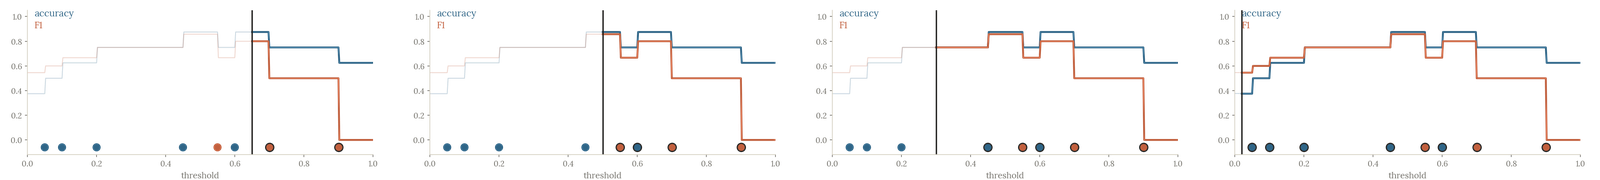

**Hỏi nhanh.** Vẫn tám xác suất ấy, nhưng đặt threshold 0.58. Accuracy và F1 bằng bao nhiêu?

- A. 0.875 và 0.8
- B. 0.75 và 0.8
- C. 0.75 và 2/3
- D. 0.875 và 2/3

<details><summary>Đáp án</summary>

C. 0.75 và 2/3

Threshold 0.58 giữ lại 0.9, 0.7 và 0.6. Ta có TP 2, FP 1 là ảnh âm 0.6, FN 1 là ảnh dương 0.55, và TN 4. Accuracy bằng $(2 + 4)/8 = 0.75$, F1 bằng $4/(4 + 1 + 1) = 2/3$. Cặp 0.875 và 0.8 là của threshold 0.65. Dịch threshold qua ảnh âm 0.6 đổi một FP thành TN, nên hình có một bậc nhảy đúng tại 0.6.

</details>

Chọn threshold trên validation là một bước tuning. F1 tốt nhất trong các ứng viên là ước lượng lạc quan cho dữ liệu mới, nhất là khi validation nhỏ; muốn một con số không thiên lệch thì cần một tập để riêng, hoặc ghi rõ đó là điểm validation sau tuning.

## Schema và ID: việc nhỏ có thể làm mất cả bài

Prediction phải đi với đúng ID, không chỉ đúng số hàng. Thứ tự file do hệ điều hành trả có thể khác sample submission. Ta ghép theo ID rồi đưa về thứ tự của sample, không dựa vào thứ tự tình cờ.

In [ ]:
import pandas as pd

sample = pd.DataFrame({"image_id": ["a", "b", "c"]})
predictions = pd.DataFrame({"image_id": ["c", "a", "b"],
                            "label": [1, 0, 1]})
assert predictions["image_id"].is_unique
assert set(predictions["image_id"]) == set(sample["image_id"])
submission = sample.merge(predictions, on="image_id", how="left", validate="one_to_one")
assert submission["label"].notna().all()
print(submission.to_string(index=False))

image_id  label
       a      0
       b      1
       c      1


Nhãn của `a` là 0 dù `a` ở hàng thứ hai của prediction. Với detection hay RLE, một ID có thể lặp cho nhiều vật thể hoặc đi với chuỗi rỗng; kiểm theo schema của đề, không áp `is_unique` cho mọi định dạng.



**Hỏi nhanh.** Prediction có đúng ba hàng như sample, nhưng ID xếp theo thứ tự khác. Ghi file nộp thế nào?

- A. Ghép theo ID, rồi giữ thứ tự của sample
- B. Chép cột nhãn sang sample theo vị trí hàng
- C. Sắp prediction theo score giảm dần rồi chép
- D. Giữ thứ tự prediction, chỉ đổi tên cột cho khớp

<details><summary>Đáp án</summary>

A. Ghép theo ID, rồi giữ thứ tự của sample

Thứ tự hàng không phải khóa, ID mới là khóa. Chép theo vị trí sẽ gán nhãn của `c` cho `a`. Sắp theo score tạo ra một thứ tự thứ ba, chẳng liên quan gì đến sample. Giữ thứ tự prediction chỉ đúng nếu scorer ghép theo ID, điều mà đề thường không hứa. Hãy ghép theo ID, rồi assert số hàng, tập ID và không có giá trị thiếu.

</details>

Nạp lại checkpoint phải kèm mapping lớp, preprocessing, kiến trúc và head, cấu hình hậu xử lý. So prediction của vài mẫu trước và sau khi nạp lại trong cùng điều kiện; khác biệt lớn là dấu hiệu thiếu một thành phần. Không dựa vào biến còn sống trong notebook.

**Hỏi nhanh.** Đội train với ảnh resize 224. Sau đó họ sửa hàm `preprocess` trong notebook thành resize 256 để thử một ý khác, rồi bỏ ý ấy nhưng quên sửa lại. Nạp checkpoint ở một tiến trình mới thì F1 validation tụt từ 0.86 xuống 0.71. Nên kiểm gì trước?

- A. Trọng số hỏng khi lưu, cần train lại từ đầu
- B. Preprocessing lúc suy luận khác lúc train
- C. Seed khác, nên F1 dao động 0.15 là bình thường
- D. Validation đã đổi, cần chia lại một split mới

<details><summary>Đáp án</summary>

B. Preprocessing lúc suy luận khác lúc train

Checkpoint chỉ lưu trọng số, còn hàm `preprocess` hiện tại resize 256, nên model nhìn vật thể ở tỉ lệ khác lúc train. CNN có global pooling vẫn chạy được với ảnh 256, nên không báo lỗi, chỉ âm thầm sai nhiều hơn. Hãy lưu cấu hình preprocessing, gồm kích thước, mean, std và thứ tự kênh, cùng với checkpoint, và đọc lại từ đó khi suy luận. Inference ở chế độ eval không có gì ngẫu nhiên, nên seed không giải thích được mức tụt 0.15. Trọng số hỏng thường báo lỗi khi nạp, hoặc cho kết quả hoàn toàn vô nghĩa.

</details>

## Khi chữa bài: đọc kết quả để chọn việc luyện tiếp

Bắt đầu bằng tính hợp lệ: scorer có đọc được file, runtime có đạt, checkpoint có nạp lại được? Sau đó mới đọc score và lỗi theo nhóm. Nếu baseline hợp lệ nhưng điểm thấp, hỏi lỗi lớn nhất nằm ở dữ liệu, preprocessing, model hay hậu xử lý.

Với classification, đọc confusion matrix và tách theo camera; với detection, tách bỏ sót, box trùng, sai lớp, lệch vị trí; với segmentation, xem ảnh rỗng và vùng mảnh; với retrieval, tách sai đối tượng, hành động và quan hệ. Mỗi nhóm lỗi gợi một thí nghiệm tiếp theo, không chỉ gợi một model mới.

**Hỏi nhanh.** Detection trên validation có 300 FP. 210 trong số đó là box thứ hai nằm trên vật thể đã có box đúng, với IoU so với box đúng từ 0.6 đến 0.75. NMS hiện chỉ loại box khi IoU trên 0.8. Nên chạy thí nghiệm nào trước?

- A. Tăng độ phân giải ảnh đầu vào lên gấp đôi
- B. Train thêm epoch với đúng cấu hình hiện tại
- C. Tăng score threshold đến khi hết box trùng
- D. Hạ ngưỡng IoU của NMS xuống 0.5 rồi đo lại

<details><summary>Đáp án</summary>

D. Hạ ngưỡng IoU của NMS xuống 0.5 rồi đo lại

Nhóm lỗi lớn nhất, chiếm 70% số FP, là box trùng có IoU từ 0.6 đến 0.75. Chúng nằm dưới ngưỡng 0.8, nên NMS giữ lại. Hạ ngưỡng nhắm đúng vào nhóm này. Đo lại trên cùng validation, và xem recall ở những cảnh đông, nơi hai vật thật chồng lên nhau có thể bị gộp làm một. Box trùng thường có score gần với box đúng, nên tăng score threshold sẽ xóa cả TP. Độ phân giải và số epoch không nhắm vào nhóm lỗi đã đo.

</details>

Ghi một bảng thí nghiệm ngắn: cấu hình, split, metric, runtime, giả thuyết, kết luận. Nếu hai cấu hình chênh nhỏ, xem độ ổn định theo fold hoặc seed trong ngân sách cho phép. Không lấy cấu hình thắng một lượt trên public leaderboard thay cho validation đúng; số lượt nộp và cách chấm public tùy quy định của từng kỳ thi.

**Hỏi nhanh.** Cấu hình A có macro-F1 5-fold, chia theo nguồn, bằng 0.842, các fold lệch nhau khoảng $\pm 0.006$, và public leaderboard 0.83. Cấu hình B có $0.838 \pm 0.007$ và public 0.85. Public chỉ tính trên 60 ảnh. Nên chốt cấu hình nào?

- A. B, vì public chấm trên chính ảnh test thật
- B. A, vì validation cao hơn nên chắc chắn tốt hơn
- C. Coi như ngang nhau, nên chốt theo runtime và độ ổn định
- D. Nộp thêm nhiều lượt để public chọn hộ

<details><summary>Đáp án</summary>

C. Coi như ngang nhau, nên chốt theo runtime và độ ổn định

Trên 60 ảnh, chỉ một ảnh đổi từ đúng sang sai đã làm điểm lệch khoảng $1/60 \approx 0.017$, nên chênh public 0.02 chỉ cỡ một ảnh. Chênh validation 0.004 còn nhỏ hơn độ dao động giữa các fold. Hai cấu hình coi như ngang nhau. Khi đó hãy chọn cái chạy nhanh hơn, ít ngẫu nhiên hơn hoặc đơn giản hơn. Nộp nhiều lượt để chọn theo public là tune trên test.

</details>



## Bẫy trước khi chốt

> **Bài chạy trong notebook chưa chắc chạy ở tiến trình mới**
>
> Khởi động lại, nạp asset từ đường dẫn đã ghi, chạy inference và kiểm schema. Biến chưa lưu, thứ tự cell, module ở chế độ train hoặc processor khác có thể làm bài nộp đổi hành vi.

Đừng dành mọi phút để train rồi hết thời gian xuất file. Không âm thầm bỏ ảnh rỗng hoặc ảnh đọc lỗi khỏi output. Không đổi sang metric khác chỉ vì con số đẹp hơn. Một recipe dùng model pretrained chỉ thành pipeline khi asset đã nạp được và inference chạy hết trên validation; trước mốc đó nó chưa có điểm nào để so. Khi thiếu asset, một baseline nhỏ hợp lệ vẫn cho kết quả cụ thể để học tiếp.

**Hỏi nhanh.** Có 300 ảnh test, trong đó 3 file hỏng không đọc được. Vòng lặp inference có `try: ... except: continue`. File nộp có vấn đề gì, và sửa thế nào?

- A. Không có vấn đề gì, scorer tự bỏ qua ID không có dự đoán
- B. Xóa 3 ID khỏi sample để số hàng khớp lại
- C. Thử đọc bằng thư viện khác, vẫn lỗi thì bỏ hàng
- D. Thiếu 3 ID, nên vẫn phải ghi hàng với một dự đoán dự phòng

<details><summary>Đáp án</summary>

D. Thiếu 3 ID, nên vẫn phải ghi hàng với một dự đoán dự phòng

File chỉ còn 297 hàng. Scorer có thể từ chối cả file, hoặc tính các ID thiếu là sai. Sample là hợp đồng, không được sửa. Thử thư viện khác là bước tốt, nhưng nếu vẫn lỗi thì vẫn phải có hàng. Hãy ghi một dự đoán dự phòng, như lớp phổ biến nhất trên train hay mask rỗng, log lại ID, và assert tập ID khớp sample trước khi nộp.

</details>

## Khi đi thi

- **Có bài nộp hợp lệ thật sớm.** Baseline đi đủ đường đọc ảnh → model → hậu xử lý → file và được scorer hoặc checker nhận, trước mọi thí nghiệm lớn.
- **Đọc luật về model và dữ liệu.** Có Internet không, pretrained có được phép không (kể cả kiến trúc lấy từ thư viện), có được gán nhãn tay không; vi phạm có thể mất điểm cả bài.
- **Đo thời gian trên máy chấm.** Đo một epoch và một lượt inference toàn test ở vòng đầu, rồi lập lịch có khoản dự phòng.
- **Mỗi lượt chạy một thay đổi.** Cùng split, cùng metric của đề; ghi cấu hình, điểm, runtime vào bảng. Một số đề yêu cầu nộp kèm báo cáo các model đã thử.
- **Chốt theo validation và metric của đề.** Giữ checkpoint tốt nhất theo đúng metric ấy, kèm mapping lớp và preprocessing; không chốt theo public leaderboard nhỏ.
- **Dừng mở hướng mới trước hạn.** Khởi động lại tiến trình, nạp checkpoint, chạy đủ test, ghép theo ID với sample, kiểm số hàng và giá trị hợp lệ.

## Tóm tắt

Buổi kiểm tra đánh giá cả quy trình. Đúng task, split, preprocessing, metric và schema là nền để chọn model. Thí nghiệm tốt có giả thuyết, thay đổi rõ, điểm thật và runtime thật. Chữa bài tốt xác định việc cần luyện tiếp từ lỗi, không chỉ từ thứ hạng.

## Kiểm tra cuối bài

**Câu 1.** Đề yêu cầu train và test trên GPU L4 24 GB. Notebook không chạy được trên L4 thì phần đó 0 điểm. Đội phát triển trên A100 80 GB với batch 256, bộ nhớ đỉnh đo được là 41 GB. Trước khi nộp nên làm gì?

- A. Giữ nguyên, vì A100 chạy được thì L4 cũng chạy, chỉ chậm hơn
- B. Giảm batch và tích lũy gradient, rồi chạy lại cả notebook trên L4
- C. Nộp checkpoint train trên A100, notebook chỉ chạy inference
- D. Ghi trong báo cáo rằng notebook cần GPU 80 GB

<details><summary>Đáp án</summary>

B. Giảm batch và tích lũy gradient, rồi chạy lại cả notebook trên L4

41 GB vượt 24 GB, nên notebook hết bộ nhớ ngay epoch đầu, tức 0 điểm. Đề yêu cầu train trên L4, nên nộp checkpoint train ở nơi khác là trái luật. Báo cáo cũng không thay được luật. Batch 64 tích lũy 4 bước giữ batch hiệu dụng 256 (bài 3.7). Sau đó chạy lại toàn bộ notebook từ đầu trên L4 để đo cả bộ nhớ lẫn thời gian.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Part 1.4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=8)

</details>

**Câu 2.** Đề hình học có 200 ảnh có nhãn và 800 ảnh không nhãn, chấm macro-F1, chỉ cho gán nhãn bằng code. Đội train model A trên 160 ảnh có nhãn, để 40 ảnh làm validation. Sau đó họ gán nhãn giả cho những ảnh mà A tự tin trên 0.95, được 520 ảnh, gồm 400 hình tròn, 90 chữ nhật và 30 tam giác. Model B train trên $160 + 520$ ảnh có macro-F1 validation 0.77, thấp hơn A là 0.81, và recall của tam giác tụt mạnh. Nên thử gì trước?

- A. Hạ ngưỡng tin cậy xuống 0.5 để có thêm ảnh
- B. Lấy số nhãn giả cân bằng giữa ba lớp
- C. Bỏ hẳn ảnh không nhãn, quay về model A
- D. Train B thêm epoch cho tam giác kịp học

<details><summary>Đáp án</summary>

B. Lấy số nhãn giả cân bằng giữa ba lớp

Ngưỡng 0.95 chủ yếu giữ lại lớp mà A đã đoán dễ, tức hình tròn. Tập train vì vậy lệch hẳn về hình tròn, và lớp tam giác kéo macro-F1 xuống. Hãy lấy mỗi lớp cùng một số ảnh tự tin nhất, ví dụ 30 ảnh mỗi lớp, rồi so lại với A trên cùng 40 ảnh validation. Hạ ngưỡng thì thêm nhãn sai mà vẫn lệch lớp. Thêm epoch chỉ học kỹ hơn chính tập bị lệch. Quay về A là phương án dự phòng hợp lệ, nhưng chưa phải thí nghiệm nhắm đúng nguyên nhân.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=9)

</details>

**Câu 3.** Đề quy định nhãn 0 là tròn, 1 là tam giác, 2 là chữ nhật. Đội xếp ảnh có nhãn vào các thư mục `circle/`, `triangle/`, `rectangle/`, nạp bằng `ImageFolder`, vốn đánh mã lớp theo thứ tự tên thư mục, rồi ghi thẳng `argmax` vào file nộp. Validation macro-F1 được 0.95, nhưng điểm chấm chỉ 0.31. Nguyên nhân khả dĩ nhất là gì?

- A. Overfit, vì chỉ có 160 ảnh để train
- B. Ảnh test có màu khác hẳn ảnh train
- C. Thứ tự lớp của ImageFolder khác với mã của đề
- D. Macro-F1 phạt nặng các lớp hiếm trong test

<details><summary>Đáp án</summary>

C. Thứ tự lớp của ImageFolder khác với mã của đề

`ImageFolder` đánh số lớp theo tên thư mục xếp theo bảng chữ cái: circle là 0, rectangle là 1, triangle là 2. Tam giác và chữ nhật bị đổi mã cho nhau, nên hai trong ba lớp gần như sai hết, và macro-F1 chỉ còn khoảng $(0.95 + 0 + 0)/3 \approx 0.32$. Validation không phát hiện ra, vì nó dùng cùng mapping. Overfit hay đổi màu làm điểm giảm dần, hiếm khi rơi đúng về khoảng một phần ba. Hãy ghi mapping tường minh `{"circle": 0, "triangle": 1, "rectangle": 2}` và lưu cùng checkpoint.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 2 · Problem 4](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-2-problems.pdf#page=8)

</details>

**Câu 4.** Validation detection có 8 vật thể thật. Model trả về 7 box sau NMS. Ghép theo IoU từ 0.5 trở lên thì có 5 box khớp với 5 vật thể khác nhau. F1 bằng bao nhiêu?

- A. 2/3
- B. 5/7
- C. 5/8
- D. 5/6

<details><summary>Đáp án</summary>

A. 2/3

TP là 5, FP là $7 - 5 = 2$, FN là $8 - 5 = 3$, nên F1 bằng $10/(10 + 2 + 3) = 2/3$. 5/7 là precision. 5/8 là recall. 5/6 là quên FN trong mẫu số.

</details>

**Câu 5.** Đề phân loại 4 lớp chấm bằng MAP@3. Mỗi ảnh được nộp tối đa 3 nhãn theo thứ tự. Ảnh được $1/k$ điểm nếu nhãn đúng ở vị trí $k$, và 0 điểm nếu nhãn đúng không có mặt. Một ảnh có nhãn thật là B, còn model cho A 0.5, B 0.3, C 0.15, D 0.05. Nộp `A B C` và nộp chỉ `A` thì ảnh này được bao nhiêu điểm?

- A. 1 và 0
- B. 0.95 và 0.5
- C. 1/2 và 0
- D. 0.3 và 0

<details><summary>Đáp án</summary>

C. 1/2 và 0

Với `A B C`, nhãn đúng đứng thứ hai nên được 1/2. Nộp chỉ `A` thì nhãn đúng không có mặt, được 0. Ghi argmax như một bài phân loại thường sẽ mất toàn bộ điểm của những ảnh có nhãn đúng xếp thứ hai, thứ ba. 1 là coi top-3 như đúng hoặc sai. 0.3 là nhầm xác suất với điểm thứ hạng. 0.95 và 0.5 là cộng xác suất của các nhãn đã nộp. Đề này cần một thứ hạng, không cần một nhãn.

</details>

**Câu 6.** Ảnh train đều là JPEG ba kênh, nền trắng. Đọc thử tập test thì thấy 12 file PNG bốn kênh, tức RGBA. Vùng nền có alpha bằng 0, nghĩa là trong suốt, và giá trị RGB bên dưới bằng 0. Đưa 12 ảnh này vào model thế nào?

- A. Bỏ kênh alpha, giữ ba kênh RGB như đã lưu
- B. Bỏ 12 ảnh, ghi lớp phổ biến nhất cho các ID đó
- C. Thêm kênh alpha vào conv đầu, train lại với 4 kênh
- D. Dán ảnh lên nền trắng theo alpha, rồi đổi sang RGB

<details><summary>Đáp án</summary>

D. Dán ảnh lên nền trắng theo alpha, rồi đổi sang RGB

Bỏ alpha, cũng là việc `convert("RGB")` làm với ảnh RGBA, sẽ làm lộ giá trị RGB bằng 0 ở vùng trong suốt. Nền thành màu đen, một kiểu ảnh model chưa từng gặp, và hình màu tối có thể hòa vào nền. Dán lên một ảnh trắng theo alpha bằng `Image.alpha_composite`, rồi mới đổi sang RGB, thì được đúng ảnh mà trình xem hiển thị, và đúng phân phối của train. Dự đoán dự phòng chỉ dành cho file không đọc được, còn 12 file này đọc được. Ảnh train không có alpha, nên kênh thứ tư luôn bằng 1 lúc train, và model không học được gì từ nó. Sửa xong, hãy vẽ vài ảnh đã đọc ra trước khi chạy cả tập.

</details>

**Câu 7.** Ảnh chụp bằng điện thoại, box do người gán nhãn vẽ trên trình xem ảnh. Đọc ảnh bằng PIL rồi vẽ box thì khoảng 15% ảnh hiện ra nằm ngang, và box lệch hẳn khỏi vật. Ở các ảnh còn lại, box khớp. Nguyên nhân khả dĩ nhất là gì?

- A. Cờ xoay EXIF bị bỏ qua khi đọc ảnh
- B. Box của 15% ảnh bị ghép nhầm ID ảnh
- C. Box dạng `xywh` bị đọc thành `xyxy`
- D. Resize làm lệch box ở những ảnh khác tỉ lệ

<details><summary>Đáp án</summary>

A. Cờ xoay EXIF bị bỏ qua khi đọc ảnh

Điện thoại thường lưu điểm ảnh theo hướng của cảm biến, kèm một cờ EXIF báo cần xoay. Trình xem ảnh áp dụng cờ ấy, còn `Image.open` thì không. Vì vậy đúng những ảnh có cờ xoay hiện ra nằm ngang, và box vẽ trên ảnh đã xoay thì lệch khỏi vật. Hãy gọi `ImageOps.exif_transpose` ngay sau khi đọc, cả lúc train lẫn lúc dự đoán, rồi vẽ lại. Nhầm `xywh` làm sai mọi ảnh chứ không riêng ảnh nằm ngang. Ghép nhầm ID không liên quan đến hướng ảnh. Resize đúng cách thì co box theo cùng tỉ lệ với ảnh.

</details>

**Câu 8.** Mỗi mẫu là một tensor `(64, 64, 2)`, gồm hai thành phần $(F_x, F_y)$ của một trường lực xuyên tâm đo trên lưới đều phủ $[-1, 1]^2$, cột ứng với trục $x$. Xuyên tâm nghĩa là mỗi vector nằm dọc đường nối với nguồn, và độ lớn $f(r)$ chỉ phụ thuộc khoảng cách $r$ tới nguồn. Nhãn là tọa độ nguồn $(x_s, y_s)$ và 100 giá trị cường độ $f(r_i)$. Đội muốn thêm dữ liệu bằng phép lật trái–phải $x \to -x$. Ngoài việc đảo thứ tự cột của lưới, còn phải đổi gì?

- A. Không đổi gì thêm, vì lật chỉ dời vị trí các ô
- B. Đổi dấu $x_s$, giữ nguyên hai kênh và 100 cường độ
- C. Đổi dấu kênh $F_x$ và $x_s$, đảo thứ tự 100 cường độ
- D. Đổi dấu kênh $F_x$ và $x_s$, giữ nguyên 100 cường độ

<details><summary>Đáp án</summary>

D. Đổi dấu kênh $F_x$ và $x_s$, giữ nguyên 100 cường độ

Phép lật $M(x, y) = (-x, y)$ tác động lên cả vị trí lẫn mũi tên. Trường mới tại $\mathbf r$ là $M\mathbf F(M\mathbf r)$, nên $F_x$ đổi dấu, còn $F_y$ giữ nguyên. $M$ giữ nguyên khoảng cách, nên kết quả vẫn là một trường xuyên tâm, với nguồn $(-x_s, y_s)$ và đúng hàm $f$ cũ, nên 100 giá trị cường độ không đổi. Chỉ đảo cột mà giữ $F_x$ thì các mũi tên lệch khỏi đường nối với nguồn mới, không còn là một mẫu hợp lệ của đề. Giữ $x_s$ thì target bị sai chỗ. Cường độ đo theo khoảng cách chứ không theo trái phải, nên không đảo. Có thể kiểm bằng code: sinh trường từ nguồn $(-x_s, y_s)$ rồi so với tensor đã lật.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 2 · Ngày 1 · Problem 2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-2-day-1-problems.pdf#page=11)

</details>

**Câu 9.** Bài retrieval ảnh–câu fine-tune hai encoder bằng contrastive loss. Recall@1 trên validation là 0.62. Tách lỗi ra thì thấy phần lớn câu bị xếp sai có từ chỉ hướng, như “cốc bên trái laptop”. Augmentation đang lật ngang ảnh với xác suất 0.5. Nên thử gì trước?

- A. Tắt lật ngang, hoặc đổi trái và phải trong câu khi lật
- B. Tăng batch để contrastive có thêm cặp âm
- C. Train thêm epoch để học quan hệ không gian
- D. Đổi sang encoder ảnh lớn hơn, giữ nguyên dữ liệu

<details><summary>Đáp án</summary>

A. Tắt lật ngang, hoặc đổi trái và phải trong câu khi lật

Lật ngang ảnh mà giữ nguyên câu sẽ tạo ra cặp sai: một nửa số lần, “bên trái” đi với ảnh có cốc nằm bên phải. Những cặp mâu thuẫn này dạy model bỏ qua hướng, đúng nhóm lỗi đã đo. Batch lớn, train lâu hay encoder lớn đều tiếp tục học trên chính những cặp mâu thuẫn ấy. Hãy tắt lật, rồi đo lại recall@1 riêng trên nhóm câu có từ chỉ hướng.

</details>

**Câu 10.** Đề chấm macro-F1. Đội lưu checkpoint theo validation loss thấp nhất, được epoch 12 với loss 0.41 và macro-F1 0.80. Epoch 18 có loss 0.47 nhưng macro-F1 0.84 trên cùng validation. Nên nộp checkpoint nào?

- A. Epoch 12, vì loss thấp hơn thì model tổng quát hơn
- B. Epoch 18, vì đề chấm macro-F1 chứ không chấm loss
- C. Trung bình trọng số của hai epoch cho chắc
- D. Epoch 12, vì loss tăng sau đó là dấu hiệu overfit

<details><summary>Đáp án</summary>

B. Epoch 18, vì đề chấm macro-F1 chứ không chấm loss

Cross-entropy và macro-F1 có thể đi ngược chiều nhau. Loss tăng khi model quá tự tin vào vài mẫu sai, trong khi nhiều quyết định argmax đã đúng hơn. Đề chấm macro-F1 thì chọn checkpoint theo macro-F1 trên cùng validation, kèm kiểm độ ổn định nếu chênh lệch nhỏ. Tiêu chí lưu checkpoint nên đặt từ trước, bằng chính metric của đề. Lưu theo loss là đặt lệch tiêu chí ngay từ đầu. Trung bình trọng số là một thí nghiệm khác, phải đo riêng mới biết.

</details>

## Đọc thêm

- [PyTorch — Object Detection Finetuning Tutorial](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html): ôn dataset/target và inference cho box/mask.
- [TorchVision — Transforms](https://docs.pytorch.org/vision/stable/transforms.html): kiểm biến đổi đồng bộ ảnh–nhãn.
- [PyTorch — Saving and Loading Models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html): ôn thành phần checkpoint và nạp lại để suy luận.

Nguồn ảnh: ảnh hoa và ảnh tháp là ảnh mẫu `flower.jpg` (vultilion, Flickr, CC BY 2.0) và `china.jpg` (danielbuechele, Flickr, CC BY 2.0) kèm scikit-learn.